<a href="https://colab.research.google.com/github/Existanze54/sirius-machine-learning-2026/blob/main/Seminars/S5_SVM.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Семинар 5. Support Vector Machines

### Давайте импортируем все разом

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.svm import SVC

from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

## Часть 1. Maximum margin classifier

### Подготовка данных

Продолжим работать с ирисами Фишера. Для простоты оставим только два признака и два класса.

In [2]:
from sklearn.datasets import load_iris

iris = load_iris()
X = iris['data'][:, (2, 3)] # petal length, petal width
y = iris['target']

setosa_or_versicolor = (y == 0) | (y == 1)
X = X[setosa_or_versicolor]
y = y[setosa_or_versicolor] == 1

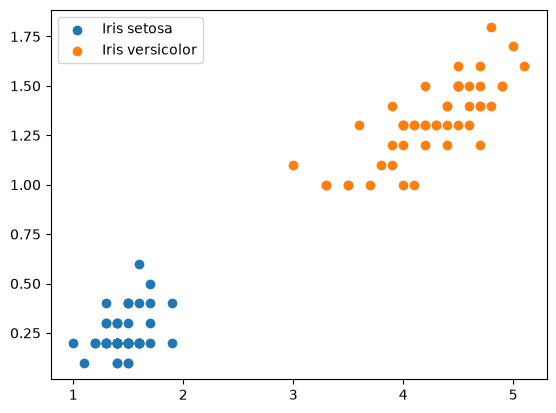

In [3]:
plt.scatter(X[~y, 0], X[~y, 1])
plt.scatter(X[y, 0], X[y, 1])

plt.legend(['Iris setosa', 'Iris versicolor'])

plt.show()

### Изображение решающих границ

In [ ]:
# Функция с просторов интернета
def plot_svc_decision_boundary(svm_clf, xmin, xmax):
    w = svm_clf.coef_[0]
    b = svm_clf.intercept_[0]

    # At the decision boundary, w0*x0 + w1*x1 + b = 0 => x1 = -w0/w1 * x0 - b/w1
    x0 = np.linspace(xmin, xmax, 200)
    decision_boundary = -w[0]/w[1] * x0 - b/w[1]

    margin = 1/w[1]
    gutter_up = decision_boundary + margin
    gutter_down = decision_boundary - margin

    svs = svm_clf.support_vectors_
    plt.scatter(svs[:, 0], svs[:, 1], s=180, facecolors='#FFAAAA')
    plt.plot(x0, decision_boundary, 'k-', linewidth=2)
    plt.plot(x0, gutter_up, 'k--', linewidth=2)
    plt.plot(x0, gutter_down, 'k--', linewidth=2)

In [ ]:
svm = SVC(kernel='linear', C=np.inf).fit(X, y)
plot_svc_decision_boundary(svm, 1, 5)

plt.scatter(X[~y, 0], X[~y, 1])
plt.scatter(X[y, 0], X[y, 1])

plt.ylim([-1, 2.5])
plt.show()

### Но что если добавить выброс?

In [ ]:
X = np.vstack([X, [3.2, 0.8]])
y = np.hstack([y, [False]])

In [ ]:
svm = SVC(kernel='linear', C=np.inf).fit(X, y)
plot_svc_decision_boundary(svm, 1, 5)

plt.scatter(X[~y, 0], X[~y, 1])
plt.scatter(X[y, 0], X[y, 1])

plt.ylim([-1, 2.5])
plt.show()

## Часть 2. Soft margin classifier

### Подготовка данных

In [ ]:
iris = load_iris()
X = iris['data'][:, (2, 3)] # petal length, petal width
y = iris['target']

versicolor_or_virginica = (y == 1) | (y == 2)
X = X[versicolor_or_virginica]
y = y[versicolor_or_virginica] == 2

In [ ]:
plt.scatter(X[~y, 0], X[~y, 1])
plt.scatter(X[y, 0], X[y, 1])

plt.legend(['Iris versicolor', 'Iris virginica'])

plt.show()

### Задача

Обучите `SVC` со значениями `C` равными 0.1, 1 и 10. Изобразите решающую границу отдельно для всех трех случаев, используя функцию выше. Стандартизуйте признаки. Изменятся ли границы?

In [ ]:
# your code here

## Часть 3. Обобщение на нелинейный случай

In [ ]:
from sklearn.datasets import make_moons

X, y = make_moons(n_samples=200, noise=0.25, random_state=42)

plt.scatter(x=X[:, 0], y=X[:, 1], c=y)
plt.show()

In [ ]:
from sklearn.inspection import DecisionBoundaryDisplay

fig, ax = plt.subplots()

svm = SVC(kernel='sigmoid').fit(X, y)
DecisionBoundaryDisplay.from_estimator(
    svm, X,
    response_method='decision_function',
    alpha=0.75,
    cmap=plt.cm.RdBu,
    ax=ax,
)

ax.scatter(X[:, 0], X[:, 1], c=y, cmap=plt.cm.RdBu)

plt.show()

Постройте решающие границы, как в примере выше, но для SVM с полиномиальным ядром (`kernel='poly'`) и различными степенями (2, 3, 5), а так же с ядром `'rbf'`.

In [ ]:
# your code here